In [109]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
X_raw, _ = make_blobs(n_samples=500, n_features=3, 
                      centers=5, cluster_std=1.5, random_state=42)

In [110]:
customer_df= pd.DataFrame(X_raw, columns= ['recency_days', 'purchase_frequency', 'annual_spend'])

In [111]:
customer_df['recency_days'] = customer_df['recency_days'].abs().round().astype(int)
customer_df['purchase_frequency'] = customer_df['purchase_frequency'].abs().round().astype(int)
customer_df['annual_spend'] = (customer_df['annual_spend'].abs()*100).round(2)

In [112]:
customer_df.head()

,recency_days,purchase_frequency,annual_spend
0,5,7,847.42
1,2,9,579.08
2,1,8,662.55
3,6,10,592.36
4,4,9,572.41


In [113]:
customer_df.describe()

,recency_days,purchase_frequency,annual_spend
count,500.000000,500.000000,500.000000
mean,4.874000,7.736000,590.812360
std,2.896706,2.032379,287.862897
min,0.000000,2.000000,0.310000
25%,3.000000,6.000000,383.820000
50%,4.500000,8.000000,596.000000
75%,7.000000,9.000000,785.267500
max,13.000000,13.000000,1380.480000


In [114]:
customer_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   recency_days        500 non-null    int64  
 1   purchase_frequency  500 non-null    int64  
 2   annual_spend        500 non-null    float64
dtypes: float64(1), int64(2)
memory usage: 11.8 KB


In [115]:
customer_df.duplicated().sum()

np.int64(0)

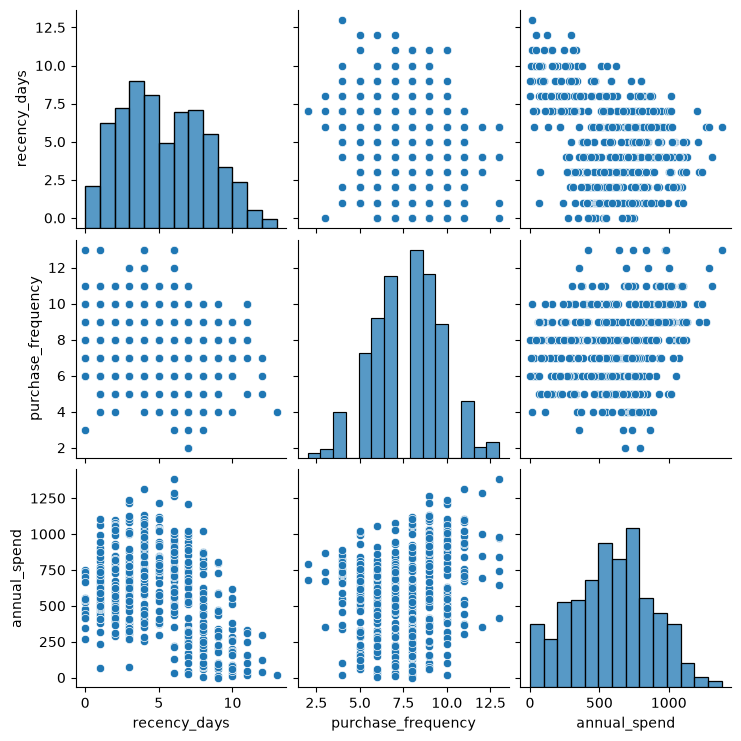

In [116]:
sns.pairplot(customer_df)

In [117]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score


In [118]:
inertia_values = []
silhouette_scores = []
k_range = range(2, 11)
for k in k_range:
    pipeline= Pipeline([('scaler', StandardScaler()),
                     ('kmeans',KMeans(n_clusters=k, n_init='auto', random_state=42))])
    cluster_labels = pipeline.fit_predict(customer_df)
    current_inertia = pipeline.named_steps['kmeans'].inertia_
    inertia_values.append(current_inertia)
    score = silhouette_score(customer_df, cluster_labels)
    silhouette_scores.append(score)

<Axes: >

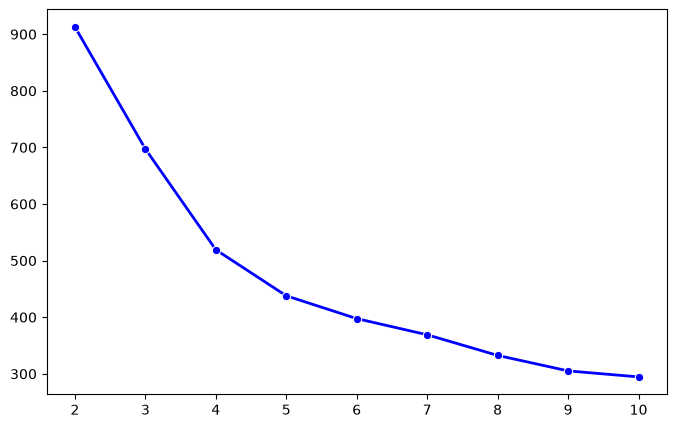

In [119]:
plt.figure(figsize=(8,5))
sns.lineplot(x= list(k_range), y=inertia_values, marker='o', color='b', linewidth=2)

Text(0.5, 1.0, 'Silhouette Analysis For Optimal K')

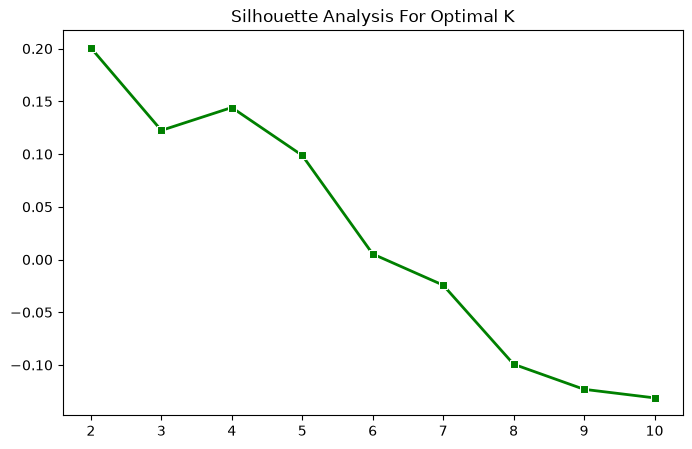

In [120]:
plt.figure(figsize=(8, 5))
sns.lineplot(x=list(k_range), y=silhouette_scores, marker='s', color='g', linewidth=2)

plt.title('Silhouette Analysis For Optimal K')

In [121]:
customer_df['segment_id'] = cluster_labels

In [122]:
customer_df['segment_id'].value_counts()

segment_id
1    72
8    69
2    69
5    51
0    49
6    45
9    40
4    39
3    36
7    30
Name: count, dtype: int64

In [123]:
customer_df.groupby('segment_id').mean()


,recency_days,purchase_frequency,annual_spend
segment_id,,,
0,9.000000,8.367347,179.887959
1,3.722222,8.736111,904.212917
2,2.275362,7.347826,510.918116
3,1.750000,5.888889,787.676389
4,6.871795,7.666667,581.759744
5,8.392157,5.882353,205.285882
6,5.111111,10.800000,984.718444
7,5.200000,5.233333,550.198000
8,2.000000,9.840580,501.072899


Text(0.5, 1.0, 'Customer Segment Discovered via Unsupervised Pipeline')

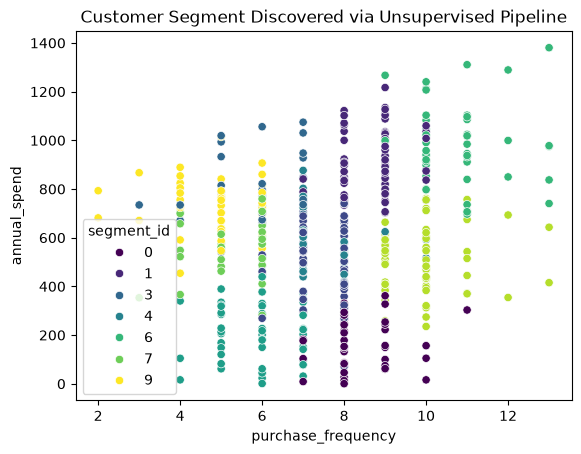

In [124]:
sns.scatterplot(data=customer_df, x='purchase_frequency', 
                y='annual_spend', hue='segment_id', palette='viridis')

plt.title('Customer Segment Discovered via Unsupervised Pipeline')